# SMS-Spam-Erkennung mit Naive Bayes

In diesem NLP-Projekt untersuche ich, wie gut ein Modell englische SMS
entweder als Spam oder als normale unbedenkliche Nachrichten erkennt.

In [1]:
from urllib.request import urlretrieve
from zipfile import ZipFile

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
urlretrieve(url, "sms_spam.zip")

with ZipFile("sms_spam.zip") as zip_datei:
    zip_datei.extract("SMSSpamCollection")

print("Die Datei ist bereit.")

Die Datei ist bereit.


In [2]:
import csv
import pandas as pd

sms = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    quoting=csv.QUOTE_NONE
)

sms.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Anzahl der SMS:", len(sms))
print(sms["label"].value_counts())

Anzahl der SMS: 5574
label
ham     4827
spam     747
Name: count, dtype: int64


In [4]:
sms["message"] = sms["message"].str.strip()
sms_clean = sms.drop_duplicates(subset="message")

print("Entfernte Duplikate:", len(sms) - len(sms_clean))
print("Verbleibende SMS:", len(sms_clean))

Entfernte Duplikate: 414
Verbleibende SMS: 5160


In [5]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    sms_clean,
    test_size=0.2,
    random_state=7,
    stratify=sms_clean["label"]
)
print("SMS für das Training:", len(train))
print("SMS für den Test:", len(test))

SMS für das Training: 4128
SMS für den Test: 1032


In [6]:
train_2000, _ = train_test_split(
    train,
    train_size=2000,
    random_state=7,
    stratify=train["label"]
)

train_500, _ = train_test_split(
    train_2000,
    train_size=500,
    random_state=7,
    stratify=train_2000["label"]
)

print("Kleine Trainingsmenge:", len(train_500))
print("Mittlere Trainingsmenge:", len(train_2000))
print("Ganze Trainingsmenge:", len(train))

Kleine Trainingsmenge: 500
Mittlere Trainingsmenge: 2000
Ganze Trainingsmenge: 4128


In [7]:
beispiel = "You are winning a FREE ticket!"
klein = beispiel.lower()
woerter = klein.split()

print(woerter)

['you', 'are', 'winning', 'a', 'free', 'ticket!']


In [8]:
sauber = klein

for zeichen in ".,!?;:":
    sauber = sauber.replace(zeichen, " ")

woerter = sauber.split()
print(woerter)

['you', 'are', 'winning', 'a', 'free', 'ticket']


In [10]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def text_vorbereiten(text):
    text = text.lower()

    for zeichen in ".,!?;:":
        text = text.replace(zeichen, " ")

    gefilterte_woerter = []
    for wort in text.split():
        if wort not in ENGLISH_STOP_WORDS:
            wortstamm = stemmer.stem(wort)
            gefilterte_woerter.append(wortstamm)

    return " ".join(gefilterte_woerter)

texte_500 = train_500["message"].apply(text_vorbereiten)
texte_500.head()

,message
56,congrat 1 year special cinema pass 2 090612094...
405,yep great loxahatche xma tree burn &lt #&gt st...
4950,bu way calicut
2884,lor come
4280,urgent import inform 02 user today lucki day 2...


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

texte_test = test["message"].apply(text_vorbereiten)

tfidf_500 = TfidfVectorizer()
X_train_500 = tfidf_500.fit_transform(texte_500)
X_test_500 = tfidf_500.transform(texte_test)

print("Training:", X_train_500.shape)
print("Test:", X_test_500.shape)

Training: (500, 1823)
Test: (1032, 1823)


In [12]:
from sklearn.naive_bayes import MultinomialNB

modell_500 = MultinomialNB()
modell_500.fit(X_train_500, train_500["label"])

vorhersagen_500 = modell_500.predict(X_test_500)
print(vorhersagen_500[:5])

['ham' 'ham' 'ham' 'ham' 'ham']


In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    test["label"],
    vorhersagen_500,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

         ham      0.907     1.000     0.951       904
        spam      1.000     0.273     0.429       128

    accuracy                          0.910      1032
   macro avg      0.953     0.637     0.690      1032
weighted avg      0.918     0.910     0.886      1032



In [14]:
texte_2000 = train_2000["message"].apply(text_vorbereiten)
texte_2000.head()

,message
3665,huh 6 mistak
2239,think sent text home phone display text want s...
803,free 1st week no1 nokia tone 4 ur mobil week j...
1544,hello orang 1 month' free access game news spo...
2002,idea soon convert live )


In [15]:
tfidf_2000 = TfidfVectorizer()
X_train_2000 = tfidf_2000.fit_transform(texte_2000)

print(X_train_2000.shape)

(2000, 4147)


In [16]:
X_test_2000 = tfidf_2000.transform(texte_test)
print(X_test_2000.shape)

(1032, 4147)


In [17]:
modell_2000 = MultinomialNB()
modell_2000.fit(X_train_2000, train_2000["label"])

print("Modell trainiert.")

Modell trainiert.


In [18]:
vorhersagen_2000 = modell_2000.predict(X_test_2000)
print(vorhersagen_2000[:5])

['ham' 'ham' 'ham' 'ham' 'ham']


In [19]:
print(classification_report(
    test["label"],
    vorhersagen_2000,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

         ham      0.956     1.000     0.977       904
        spam      1.000     0.672     0.804       128

    accuracy                          0.959      1032
   macro avg      0.978     0.836     0.891      1032
weighted avg      0.961     0.959     0.956      1032



In [20]:
texte_alle = train["message"].apply(text_vorbereiten)
print(len(texte_alle))

4128


In [21]:
tfidf_alle = TfidfVectorizer()
X_train_alle = tfidf_alle.fit_transform(texte_alle)

print(X_train_alle.shape)

(4128, 6423)


In [22]:
X_test_alle = tfidf_alle.transform(texte_test)
print(X_test_alle.shape)

(1032, 6423)


In [23]:
modell_alle = MultinomialNB()
modell_alle.fit(X_train_alle, train["label"])

print("Modell trainiert.")

Modell trainiert.


In [24]:
vorhersagen_alle = modell_alle.predict(X_test_alle)

print(classification_report(
    test["label"],
    vorhersagen_alle,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

         ham      0.965     0.999     0.982       904
        spam      0.990     0.742     0.848       128

    accuracy                          0.967      1032
   macro avg      0.977     0.871     0.915      1032
weighted avg      0.968     0.967     0.965      1032



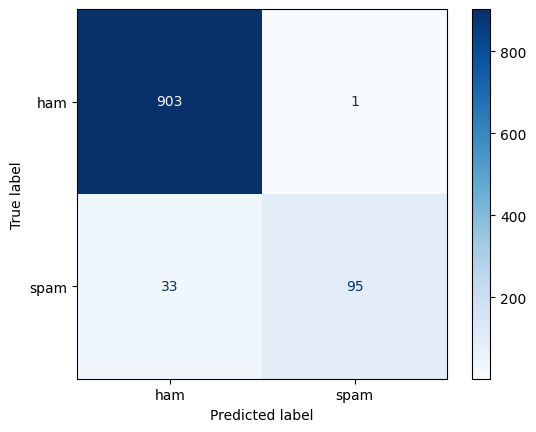

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    test["label"],
    vorhersagen_alle,
    labels=["ham", "spam"],
    cmap="Blues"
)

plt.show()

In [26]:
neue_sms = pd.Series([
    "Are we still meeting at six tonight?",
    "Congratulations! Claim your free cash prize now!"
])

neue_texte = neue_sms.apply(text_vorbereiten)
X_neu = tfidf_alle.transform(neue_texte)
print(modell_alle.predict(X_neu))

['ham' 'spam']


**Datenquelle**: Almeida, T. & Hidalgo, J. (2011). *SMS Spam Collection* [Datensatz]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CC84

## Ergebnisse

Alle drei Modelle wurden mit denselben 1.032 Test-SMS geprüft. Davon waren 128 Spam.

| Trainings-SMS | Accuracy | Spam-Recall | Spam erkannt |
|---:|---:|---:|---:|
| 500 | 91,0 % | 27,3 % | 35 von 128 |
| 2.000 | 95,9 % | 67,2 % | 86 von 128 |
| 4.128 | 96,7 % | 74,2 % | 95 von 128 |

Der größte Anstieg beim Spam-Recall zeigte sich zwischen 500 und 2.000 Trainings-SMS.